In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
data = {
    "Student_ID": range(1, 21),
    "Study_Hours": [2, 3, 4, 5, 1, 6, 3, 7, 4, 8, 2, 5, 6, 3, 7, 4, 8, 5, 6, 2],
    "Attendance": [60, 70, 75, 80, 55, 90, 65, 95, 78, 98, 58, 82, 88, 68, 92, 76, 96, 85, 89, 62],
    "Maths": [45, 55, 65, 70, 40, 85, 58, 92, 68, 96, 42, 75, 82, 60, 90, 67, 98, 78, 86, 48],
    "Science": [50, 58, 68, 72, 42, 88, 60, 94, 70, 97, 45, 77, 84, 62, 91, 69, 99, 80, 87, 49],
    "English": [55, 60, 70, 75, 48, 82, 62, 90, 72, 95, 50, 78, 85, 65, 88, 71, 96, 81, 86, 53]
}

df = pd.DataFrame(data)
df.loc[4, "Maths"] = np.nan
df.loc[10, "Attendance"] = np.nan
df.loc[14, "Science"] = np.nan

print(df.head())

   Student_ID  Study_Hours  Attendance  Maths  Science  English
0           1            2        60.0   45.0     50.0       55
1           2            3        70.0   55.0     58.0       60
2           3            4        75.0   65.0     68.0       70
3           4            5        80.0   70.0     72.0       75
4           5            1        55.0    NaN     42.0       48


In [3]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nDataset information:")
df.info()

Dataset shape: (20, 6)

Column names:
['Student_ID', 'Study_Hours', 'Attendance', 'Maths', 'Science', 'English']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Student_ID   20 non-null     int64  
 1   Study_Hours  20 non-null     int64  
 2   Attendance   19 non-null     float64
 3   Maths        19 non-null     float64
 4   Science      19 non-null     float64
 5   English      20 non-null     int64  
dtypes: float64(3), int64(3)
memory usage: 1.1 KB


In [4]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Student_ID     0
Study_Hours    0
Attendance     1
Maths          1
Science        1
English        0
dtype: int64


In [5]:
df["Attendance"] = df["Attendance"].fillna(df["Attendance"].median())
df["Maths"] = df["Maths"].fillna(df["Maths"].median())
df["Science"] = df["Science"].fillna(df["Science"].median())

print("Missing values handled successfully!")
print(df.isnull().sum())

Missing values handled successfully!
Student_ID     0
Study_Hours    0
Attendance     0
Maths          0
Science        0
English        0
dtype: int64


In [6]:
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Dataset shape after removing duplicates:", df.shape)

Duplicate rows: 0
Dataset shape after removing duplicates: (20, 6)


In [7]:
df["Total_Marks"] = df[["Maths", "Science", "English"]].sum(axis=1)
df["Average_Marks"] = df[["Maths", "Science", "English"]].mean(axis=1)

print(df[["Student_ID", "Total_Marks", "Average_Marks"]].head())

   Student_ID  Total_Marks  Average_Marks
0           1        150.0      50.000000
1           2        173.0      57.666667
2           3        203.0      67.666667
3           4        217.0      72.333333
4           5        160.0      53.333333


In [8]:
def performance_category(mark):
    if mark >= 85:
        return "Excellent"
    elif mark >= 70:
        return "Good"
    elif mark >= 50:
        return "Average"
    else:
        return "Needs Improvement"

df["Performance"] = df["Average_Marks"].apply(performance_category)

print(df[["Student_ID", "Average_Marks", "Performance"]])

    Student_ID  Average_Marks        Performance
0            1      50.000000            Average
1            2      57.666667            Average
2            3      67.666667            Average
3            4      72.333333               Good
4            5      53.333333            Average
5            6      85.000000          Excellent
6            7      60.000000            Average
7            8      92.000000          Excellent
8            9      70.000000               Good
9           10      96.000000          Excellent
10          11      45.666667  Needs Improvement
11          12      76.666667               Good
12          13      83.666667               Good
13          14      62.333333            Average
14          15      82.666667               Good
15          16      69.000000            Average
16          17      97.666667          Excellent
17          18      79.666667               Good
18          19      86.333333          Excellent
19          20      

In [9]:
print(df.describe())

       Student_ID  Study_Hours  Attendance      Maths    Science   English  \
count    20.00000    20.000000   20.000000  20.000000  20.000000  20.00000   
mean     10.50000     4.550000   79.200000  71.500000  71.050000  73.10000   
std       5.91608     2.089447   12.717994  16.878825  17.242771  14.97331   
min       1.00000     1.000000   55.000000  42.000000  42.000000  48.00000   
25%       5.75000     3.000000   69.500000  59.500000  59.500000  61.50000   
50%      10.50000     4.500000   80.000000  70.000000  70.000000  73.50000   
75%      15.25000     6.000000   89.250000  85.250000  84.750000  85.25000   
max      20.00000     8.000000   98.000000  98.000000  99.000000  96.00000   

       Total_Marks  Average_Marks  
count    20.000000      20.000000  
mean    215.650000      71.883333  
std      47.802527      15.934176  
min     137.000000      45.666667  
25%     178.250000      59.416667  
50%     213.500000      71.166667  
75%     252.000000      84.000000  
max     2

In [10]:
print("Average attendance:", round(df["Attendance"].mean(), 2))
print("Highest attendance:", df["Attendance"].max())
print("Lowest attendance:", df["Attendance"].min())

low_attendance = df[df["Attendance"] < 75]
print("\nStudents with attendance below 75%:")
print(low_attendance[["Student_ID", "Attendance", "Average_Marks"]])

Average attendance: 79.2
Highest attendance: 98.0
Lowest attendance: 55.0

Students with attendance below 75%:
    Student_ID  Attendance  Average_Marks
0            1        60.0      50.000000
1            2        70.0      57.666667
4            5        55.0      53.333333
6            7        65.0      60.000000
13          14        68.0      62.333333
19          20        62.0      50.000000


Average marks by subject:
Maths      71.50
Science    71.05
English    73.10
dtype: float64


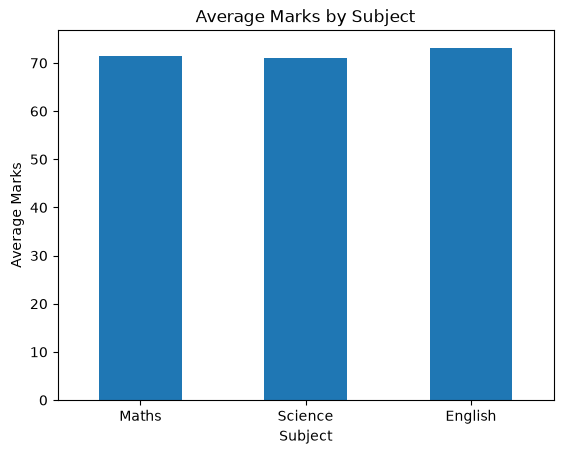

In [11]:
subject_averages = df[["Maths", "Science", "English"]].mean()

print("Average marks by subject:")
print(subject_averages)

subject_averages.plot(kind="bar")
plt.title("Average Marks by Subject")
plt.xlabel("Subject")
plt.ylabel("Average Marks")
plt.xticks(rotation=0)
plt.show()

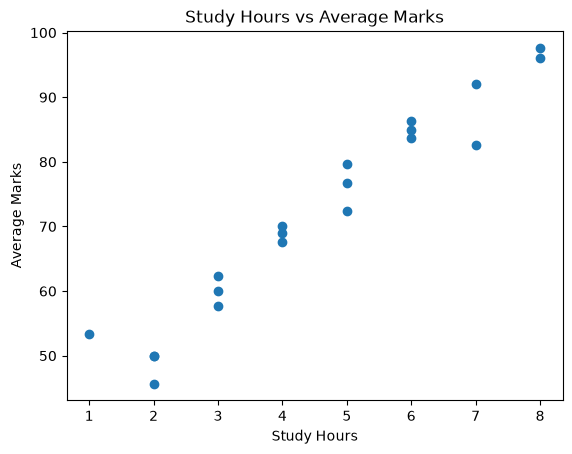

In [12]:
plt.scatter(df["Study_Hours"], df["Average_Marks"])
plt.title("Study Hours vs Average Marks")
plt.xlabel("Study Hours")
plt.ylabel("Average Marks")
plt.show()

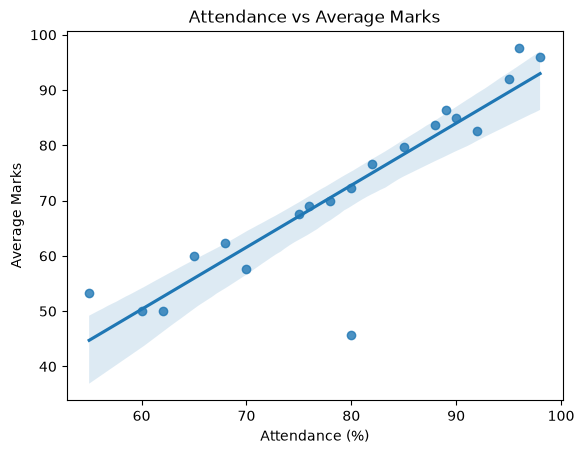

In [13]:
sns.regplot(data=df, x="Attendance", y="Average_Marks")
plt.title("Attendance vs Average Marks")
plt.xlabel("Attendance (%)")
plt.ylabel("Average Marks")
plt.show()

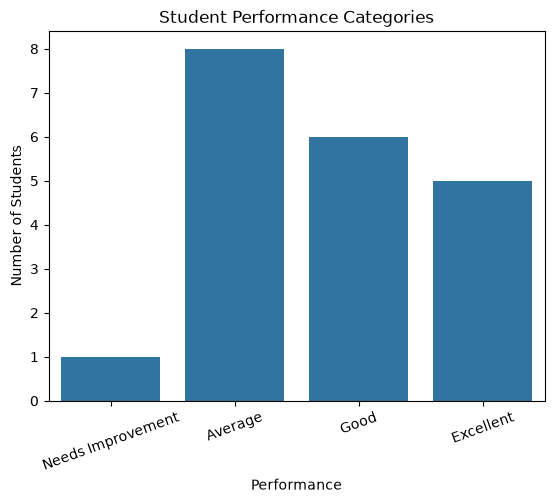

In [14]:
sns.countplot(data=df, x="Performance", order=["Needs Improvement", "Average", "Good", "Excellent"])
plt.title("Student Performance Categories")
plt.xlabel("Performance")
plt.ylabel("Number of Students")
plt.xticks(rotation=20)
plt.show()

In [15]:
numeric_columns = [
    "Study_Hours", "Attendance", "Maths",
    "Science", "English", "Average_Marks"
]

correlation_matrix = df[numeric_columns].corr()

print(correlation_matrix)

               Study_Hours  Attendance     Maths   Science   English  \
Study_Hours       1.000000    0.940388  0.912576  0.945832  0.987328   
Attendance        0.940388    1.000000  0.818167  0.886531  0.916096   
Maths             0.912576    0.818167  1.000000  0.884403  0.921926   
Science           0.945832    0.886531  0.884403  1.000000  0.964214   
English           0.987328    0.916096  0.921926  0.964214  1.000000   
Average_Marks     0.972659    0.895621  0.960884  0.975010  0.986560   

               Average_Marks  
Study_Hours         0.972659  
Attendance          0.895621  
Maths               0.960884  
Science             0.975010  
English             0.986560  
Average_Marks       1.000000  


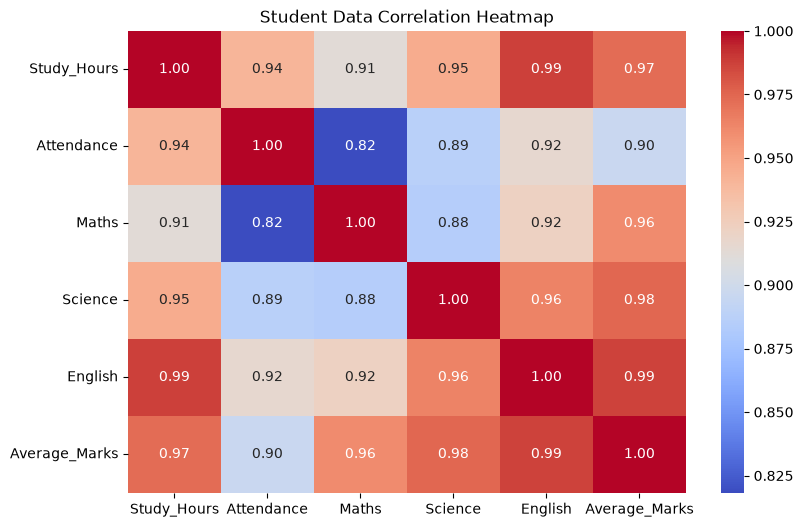

In [16]:
plt.figure(figsize=(9, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Student Data Correlation Heatmap")
plt.show()

In [17]:
features = ["Study_Hours", "Attendance", "Maths", "Science", "English"]

X = df[features]
y = df["Average_Marks"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   Study_Hours  Attendance  Maths  Science  English
0            2        60.0   45.0     50.0       55
1            3        70.0   55.0     58.0       60
2            4        75.0   65.0     68.0       70
3            5        80.0   70.0     72.0       75
4            1        55.0   70.0     42.0       48

Target:
0    50.000000
1    57.666667
2    67.666667
3    72.333333
4    53.333333
Name: Average_Marks, dtype: float64


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 16
Testing samples: 4


In [19]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [21]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual_Average_Marks": y_test.values,
    "Predicted_Average_Marks": y_pred.round(2)
})

print(results)

   Actual_Average_Marks  Predicted_Average_Marks
0             50.000000                    50.00
1             79.666667                    79.67
2             69.000000                    69.00
3             57.666667                    57.67


In [22]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R-squared (R2):", round(r2, 2))

Mean Absolute Error (MAE): 0.0
Mean Squared Error (MSE): 0.0
Root Mean Squared Error (RMSE): 0.0
R-squared (R2): 1.0


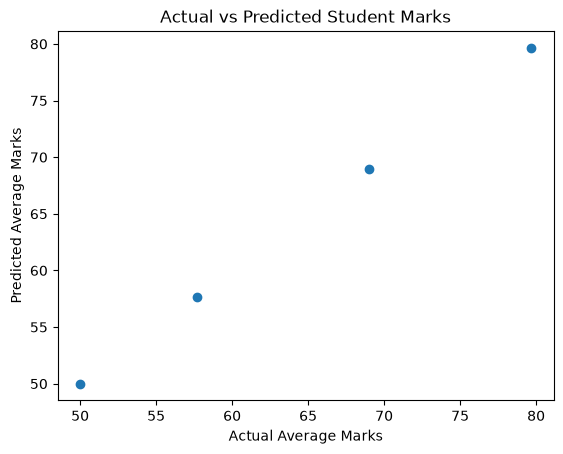

In [23]:
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Average Marks")
plt.ylabel("Predicted Average Marks")
plt.title("Actual vs Predicted Student Marks")
plt.show()

In [24]:
df.to_csv("cleaned_student_performance.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [25]:
report = f"""
STUDENT PERFORMANCE & LEARNING ANALYTICS REPORT

Total students analyzed: {len(df)}

Average student marks: {df['Average_Marks'].mean():.2f}

Average attendance: {df['Attendance'].mean():.2f}%

Average study hours: {df['Study_Hours'].mean():.2f}

Subject-wise average marks:
{subject_averages.to_string()}

Model evaluation:
MAE: {mae:.2f}
RMSE: {rmse:.2f}
R-squared: {r2:.2f}

Note: This project uses synthetic sample data for demonstration.
Model performance should not be treated as evidence of real-world
predictive accuracy.
"""

with open("student_performance_report.txt", "w", encoding="utf-8") as file:
    file.write(report)

print("Analysis report saved successfully!")

Analysis report saved successfully!


In [26]:
print("PROJECT COMPLETED SUCCESSFULLY")
print("-" * 40)
print("Total students:", len(df))
print("Average marks:", round(df["Average_Marks"].mean(), 2))
print("Average attendance:", round(df["Attendance"].mean(), 2), "%")
print("\nPerformance category counts:")
print(df["Performance"].value_counts())
print("\nFiles created:")
print("1. cleaned_student_performance.csv")
print("2. student_performance_report.txt")

PROJECT COMPLETED SUCCESSFULLY
----------------------------------------
Total students: 20
Average marks: 71.88
Average attendance: 79.2 %

Performance category counts:
Performance
Average              8
Good                 6
Excellent            5
Needs Improvement    1
Name: count, dtype: int64

Files created:
1. cleaned_student_performance.csv
2. student_performance_report.txt
